In [34]:
import pandas as pd

df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [35]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [36]:
print("Shape:", df.shape)

df.info()

df.isnull().sum()

df.duplicated().sum()

Shape: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 n

np.int64(0)

In [37]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Drop missing
df = df.dropna()

In [38]:
selected_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "Contract",
    "InternetService",
    "PaymentMethod"
]

target = "Churn"

model_df = df[selected_features + [target]].copy()

In [39]:
model_df = pd.get_dummies(model_df, drop_first=True)

In [40]:
model_df = pd.get_dummies(model_df, drop_first=True)

In [41]:
model_df = df[selected_features + [target]].copy()
model_df["Churn"] = model_df["Churn"].map({
    "No": 0,
    "Yes": 1
})
model_df = pd.get_dummies(
    model_df,
    columns=["Contract", "InternetService", "PaymentMethod"],
    drop_first=True
)

In [42]:
X = model_df.drop("Churn", axis=1)
y = model_df["Churn"]

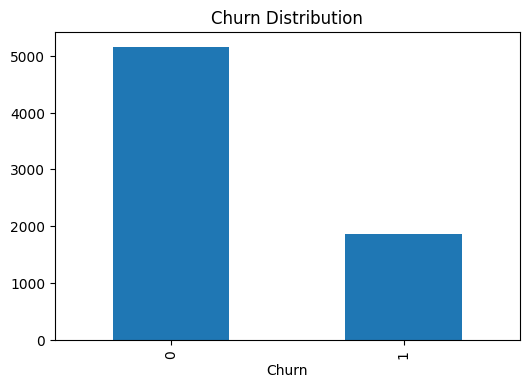

In [43]:
plt.figure(figsize=(6,4))
y.value_counts().plot(kind='bar')
plt.title("Churn Distribution")
plt.show()

In [44]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [45]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [46]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

coefficients

,Feature,Coefficient
0,tenure,-0.061220
1,MonthlyCharges,-0.003528
2,TotalCharges,0.000363
3,Contract_One year,-0.883486
4,Contract_Two year,-1.595531
5,InternetService_Fiber optic,0.998356
6,InternetService_No,-0.884314
7,PaymentMethod_Credit card (automatic),-0.127028
8,PaymentMethod_Electronic check,0.401514
9,PaymentMethod_Mailed check,-0.147899


In [47]:
print("Intercept:", model.intercept_)

Intercept: [-0.08912185]


In [48]:
y_pred = model.predict(X_test)

In [49]:
y_prob = model.predict_proba(X_test)[:, 1]

In [50]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.7924662402274343

Confusion Matrix:
[[921 112]
 [180 194]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1033
           1       0.63      0.52      0.57       374

    accuracy                           0.79      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.78      0.79      0.79      1407



In [51]:
def predict_churn(
    tenure,
    monthly_charges,
    total_charges,
    contract,
    internet_service,
    payment_method
):

    input_data = pd.DataFrame([{
        "tenure": tenure,
        "MonthlyCharges": monthly_charges,
        "TotalCharges": total_charges,
        f"Contract_{contract}": 1,
        f"InternetService_{internet_service}": 1,
        f"PaymentMethod_{payment_method}": 1
    }])

    # Align columns
    input_data = input_data.reindex(columns=X.columns, fill_value=0)

    prediction = model.predict(input_data)[0]
    probability = model.predict_proba(input_data)[0][1]

    return prediction, probability

In [52]:
!pip install -q gradio
import gradio as gr

In [53]:
def churn_inference(
    tenure,
    monthly_charges,
    total_charges,
    contract,
    internet_service,
    payment_method
):

    pred, prob = predict_churn(
        tenure,
        monthly_charges,
        total_charges,
        contract,
        internet_service,
        payment_method
    )

    return {
        "Churn Prediction": "Yes" if pred == 1 else "No",
        "Churn Probability": f"{prob:.2%}",
        "Model": "Logistic Regression"
    }

In [54]:
with gr.Blocks(title="Customer Churn Prediction") as demo:

    gr.Markdown("""
    # Customer Churn Prediction
    ### Logistic Regression Model
    """)

    tenure = gr.Number(label="Tenure", value=12)
    monthly = gr.Number(label="Monthly Charges", value=70)
    total = gr.Number(label="Total Charges", value=800)

    contract = gr.Dropdown(
        ["One year", "Two year", "Month-to-month"],
        label="Contract Type"
    )

    internet = gr.Dropdown(
        ["DSL", "Fiber optic", "No"],
        label="Internet Service"
    )

    payment = gr.Dropdown(
        [
            "Electronic check",
            "Mailed check",
            "Bank transfer (automatic)",
            "Credit card (automatic)"
        ],
        label="Payment Method"
    )

    btn = gr.Button("Predict")

    output = gr.JSON()

    btn.click(
        fn=churn_inference,
        inputs=[tenure, monthly, total, contract, internet, payment],
        outputs=output
    )

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://98a4ffbbf37086c485.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
